# 02. 아파트 특성(면적, 연식, 층)과 가격의 관계

**연구 질문 2**: 아파트의 면적, 연식, 층과 가격은 어떤 관계가 있을까?

- 사용 데이터: `data/서울_아파트_매매_실거래가_2017-2026_통합.xlsx` (2017년 10월 ~ 2026년 10월 계약분)
- 이 노트북은 특성과 가격 사이의 **통계적 관계(연관성)**를 살펴봅니다. 관계가 있다고 해서 그 특성이 가격을 올린 원인이라고 단정하지는 않습니다.

## 1. 데이터 불러오기 및 정제

01번 노트북과 같은 기준으로 정제하고, 이 질문에 필요한 기준을 더합니다.

정제 기준
1. 계약이 해제된 거래(`해제사유발생일`에 날짜가 있는 행)는 삭제합니다.
2. `NO`(일련번호)만 다르고 나머지 값이 모두 같은 행은 하나만 남깁니다.
3. `거래금액(만원)`의 쉼표를 지우고 숫자로 바꿉니다.
4. `연식` = 계약 연도 − 건축년도 로 만듭니다. 완공 전에 거래되어 연식이 음수인 행은 삭제합니다.
5. 층이 0 이하(지하층)인 거래는 일반 아파트 거래와 성격이 달라 삭제합니다.
6. 면적 차이를 줄인 가격 비교를 위해 `㎡당가격(만원)` 열을 만듭니다.

In [1]:
# 실거래가 엑셀 파일을 불러와 정제하고 연식·㎡당 가격 열을 만든다
import pandas as pd

# 1) 데이터 불러오기 (약 55만 행이라 불러오는 데 30~40초 정도 걸린다)
df = pd.read_excel('../data/서울_아파트_매매_실거래가_2017-2026_통합.xlsx')
print('원본 크기:', df.shape)

# 2) 결측치 확인
print('결측치 개수 합계:', df.isnull().sum().sum())

# 3) 계약이 해제된 거래 삭제 ('-'이면 해제되지 않은 거래)
print('해제된 거래 수:', (df['해제사유발생일'] != '-').sum())
df = df[df['해제사유발생일'] == '-']

# 4) NO만 다른 중복 거래 삭제
before = len(df)
df = df.drop_duplicates(subset=df.columns.drop('NO'))
print('삭제한 중복 거래 수:', before - len(df))

# 5) 거래금액의 쉼표를 지우고 정수로 바꾸기
df['거래금액(만원)'] = df['거래금액(만원)'].str.replace(',', '').astype(int)

# 6) 구 이름, 계약 연도 만들기
df['구'] = df['시군구'].str.split().str[1]
df['연도'] = df['계약년월'] // 100

# 7) 연식 만들기, 완공 전 거래(연식이 음수) 삭제
df['연식'] = df['연도'] - df['건축년도']
print('연식이 음수인 거래 수:', (df['연식'] < 0).sum())
df = df[df['연식'] >= 0]

# 8) 지하층(층이 0 이하) 거래 삭제
print('지하층 거래 수:', (df['층'] <= 0).sum())
df = df[df['층'] > 0]

# 9) ㎡당 가격 만들기
df['㎡당가격(만원)'] = df['거래금액(만원)'] / df['전용면적(㎡)']

# 10) 분석에 필요한 열만 남기고 인덱스 다시 매기기
df = df[['구', '단지명', '전용면적(㎡)', '층', '건축년도', '연식', '계약년월', '연도', '거래금액(만원)', '㎡당가격(만원)']]
df = df.reset_index(drop=True)

print('정제 후 크기:', df.shape)
df.describe().round(1)

원본 크기: (547735, 21)
결측치 개수 합계: 0
해제된 거래 수: 17606


삭제한 중복 거래 수: 4180


연식이 음수인 거래 수: 39
지하층 거래 수: 107
정제 후 크기: (525803, 10)


,전용면적(㎡),층,건축년도,연식,계약년월,연도,거래금액(만원),㎡당가격(만원)
count,525803.0,525803.0,525803.0,525803.0,525803.0,525803.0,525803.0,525803.0
mean,76.6,9.4,2001.6,19.9,202158.3,2021.5,97534.2,1262.9
std,29.9,6.3,10.5,10.6,290.5,2.9,77088.2,745.1
min,10.2,1.0,1961.0,0.0,201710.0,2017.0,4732.0,143.1
25%,59.7,4.0,1995.0,12.0,201908.0,2019.0,51000.0,764.8
50%,81.5,8.0,2002.0,20.0,202102.0,2021.0,77500.0,1059.8
75%,85.0,13.0,2009.0,27.0,202412.0,2024.0,120000.0,1530.7
max,395.1,69.0,2026.0,65.0,202610.0,2026.0,2900000.0,10586.7


## 2. 특성과 가격의 상관계수

면적·층·연식이 거래금액, ㎡당 가격과 얼마나 함께 움직이는지 상관계수로 확인합니다 (교재 3장·5장의 `corr()`와 히트맵 방식).

- 상관계수는 -1 ~ 1 사이 값입니다. 1에 가까우면 한쪽이 클수록 다른 쪽도 크고, -1에 가까우면 반대로 움직입니다. 0에 가까우면 직선 관계가 약합니다.
- 01번 분석에서 가격이 연도에 따라 크게 달라졌으므로 `연도`도 함께 넣어 비교합니다.
- 이상치는 지우지 않습니다. IQR 기준으로 잡히는 거래 대부분이 강남·서초·송파·용산의 정상 거래이기 때문입니다.
- 상관계수는 **두 변수가 함께 움직이는 정도**일 뿐, 한쪽이 다른 쪽의 원인이라는 뜻은 아닙니다.

          전용면적(㎡)     층    연식    연도  거래금액(만원)  ㎡당가격(만원)
전용면적(㎡)      1.00  0.10  0.02 -0.05      0.54      0.03
층            0.10  1.00 -0.19  0.03      0.17      0.16
연식           0.02 -0.19  1.00  0.15      0.01     -0.02
연도          -0.05  0.03  0.15  1.00      0.27      0.39
거래금액(만원)     0.54  0.17  0.01  0.27      1.00      0.79
㎡당가격(만원)     0.03  0.16 -0.02  0.39      0.79      1.00


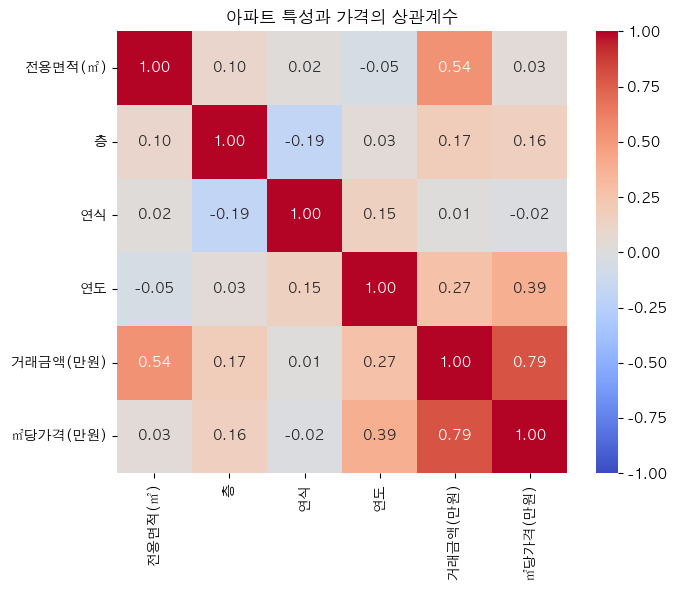

In [2]:
# 면적·층·연식·연도와 거래금액·㎡당 가격의 상관계수를 구하고 히트맵으로 그린다
import matplotlib.pyplot as plt
import seaborn as sns

# 1) 한글 폰트 설정 (맥 기본 폰트), 마이너스 기호 깨짐 방지
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

# 2) 상관계수 구하기
cols = ['전용면적(㎡)', '층', '연식', '연도', '거래금액(만원)', '㎡당가격(만원)']
corr = df[cols].corr()  # corr(): 열끼리 짝지어 피어슨 상관계수(-1~1)를 계산해 표로 돌려준다
print(corr.round(2))

# 3) 히트맵 그리기 (-1 파랑 ~ 0 흰색 ~ 1 빨강)
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('아파트 특성과 가격의 상관계수')
plt.tight_layout()
plt.savefig('../outputs/02_특성_가격_상관계수.png', dpi=150)
plt.show()

## 3. 같은 구 안에서 면적 구간별 ㎡당 가격 비교

전용면적을 6개 구간으로 나눕니다.

| 구간 | 전용면적 | 대략적인 평형(공급 기준) |
| --- | --- | --- |
| 000-040 | 40㎡ 미만 | 약 15평 이하 |
| 040-060 | 40㎡ 이상 ~ 60㎡ 미만 | 약 16~24평 |
| 060-085 | 60㎡ 이상 ~ 85㎡ 미만 | 약 25~33평 (**기준**) |
| 085-102 | 85㎡ 이상 ~ 102㎡ 미만 | 약 34~40평 |
| 102-135 | 102㎡ 이상 ~ 135㎡ 미만 | 약 41~50평 |
| 135+ | 135㎡ 이상 | 약 50평 이상 |

- 서울 전체로 묶어 비교하면, 큰 면적 거래가 강남·서초·송파·용산에 몰려 있어 지역 차이가 면적 차이처럼 보입니다. 그래서 **같은 구 안에서** 비교합니다.
- 기준은 거래가 가장 많은 **060-085 구간**(국민평형 84.9㎡ 포함)입니다. 84.9㎡가 이 구간에 들어가도록 85㎡ **미만**까지로 잡습니다.

계산 순서
1. 구마다 면적 구간별 ㎡당 가격 중앙값을 구합니다.
2. 같은 구의 060-085 구간 대비 몇 % 차이인지 계산합니다.
3. 25개 구의 차이를 평균 내어 점과 선으로 그립니다.

- 금천구는 135+ 구간 거래가 19건, 085-102 구간 거래가 적은 구도 있어(최소 26건) 해당 칸의 값은 흔들릴 수 있습니다.

         평균_차이(%)  기준보다_비싼_구_수
000-040      -1.2           11
040-060      16.4           23
060-085       0.0            0
085-102      -6.0            7
102-135     -14.4            2
135+        -19.1            3


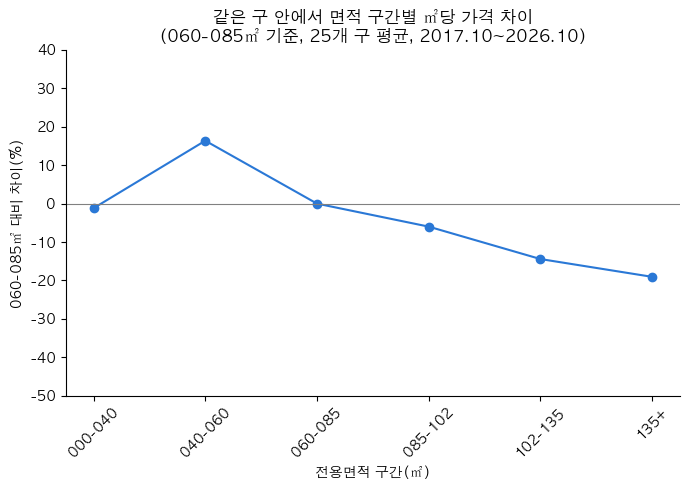

In [3]:
# 면적을 6구간으로 나누고, 같은 구의 60~85㎡ 대비 ㎡당 가격 차이(%)의 25개 구 평균을 그린다
# 1) 면적 구간 나누기 (right=False: 60이면 '060-085'처럼 왼쪽 경계를 포함)
bins = [0, 40, 60, 85, 102, 135, 1000]
labels = ['000-040', '040-060', '060-085', '085-102', '102-135', '135+']
df['면적구간'] = pd.cut(df['전용면적(㎡)'], bins=bins, labels=labels, right=False)

# 2) 구(행) × 면적구간(열) ㎡당 가격 중앙값 표 만들기
gu_size = df.pivot_table(index='구', columns='면적구간', values='㎡당가격(만원)', aggfunc='median', observed=True)

# 3) 같은 구의 060-085 구간 대비 차이(%) 구하기
gu_size_diff = pd.DataFrame()
for col in labels:
    gu_size_diff[col] = (gu_size[col] - gu_size['060-085']) / gu_size['060-085'] * 100

# 4) 25개 구의 평균 차이와 기준보다 비싼 구의 수 구하기
diff_mean = gu_size_diff.mean()
summary = pd.DataFrame({'평균_차이(%)': diff_mean,
                        '기준보다_비싼_구_수': (gu_size_diff > 0).sum()})
print(summary.round(1))

# 5) 점 + 선 그래프 그리기
plt.figure(figsize=(7, 5))
plt.plot(labels, diff_mean, marker='o', color='#2a78d6', linewidth=1.5)
plt.axhline(0, color='gray', linewidth=0.8)  # 기준선(060-085 구간 = 0%)
plt.ylim(-50, 40)
plt.title('같은 구 안에서 면적 구간별 ㎡당 가격 차이\n(060-085㎡ 기준, 25개 구 평균, 2017.10~2026.10)')
plt.xlabel('전용면적 구간(㎡)')
plt.ylabel('060-085㎡ 대비 차이(%)')
plt.xticks(rotation=45)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../outputs/02_구별_평형대별_제곱미터당가격.png', dpi=150)
plt.show()

## 4. 같은 구 안에서 층 구간별 ㎡당 가격 비교

층을 6개 구간으로 나누고, 3절과 같은 방법으로 **같은 구 안에서** 비교합니다.

| 구간 | 층 | 거래 건수 |
| --- | --- | --- |
| 1층 | 1층 (**기준**) | 약 2.7만 건 |
| 2-5층 | 2층 ~ 5층 | 약 14.1만 건 |
| 6-10층 | 6층 ~ 10층 | 약 15.8만 건 |
| 11-15층 | 11층 ~ 15층 | 약 12.2만 건 |
| 16-20층 | 16층 ~ 20층 | 약 4.9만 건 |
| 21층+ | 21층 이상 | 약 2.8만 건 |

계산 순서
1. 구마다 층 구간별 ㎡당 가격 중앙값을 구합니다.
2. 같은 구의 **1층** 대비 몇 % 차이인지 계산합니다.
3. 25개 구의 차이를 평균 내어 점과 선으로 그립니다.

- 고층 거래는 높은 건물이 있는 단지(대체로 새 아파트·대단지)에서만 나옵니다. 그래서 층 구간 사이의 차이에는 층 자체뿐 아니라 **단지 특성(연식, 단지 규모 등)의 차이**도 섞여 있을 수 있습니다.
- 종로구는 21층 이상 거래가 33건뿐이라 해당 칸의 값은 흔들릴 수 있습니다.

        평균_차이(%)  1층보다_비싼_구_수
1층           0.0            0
2-5층         3.7           21
6-10층       10.8           24
11-15층      15.0           25
16-20층      22.9           25
21층+        36.1           25


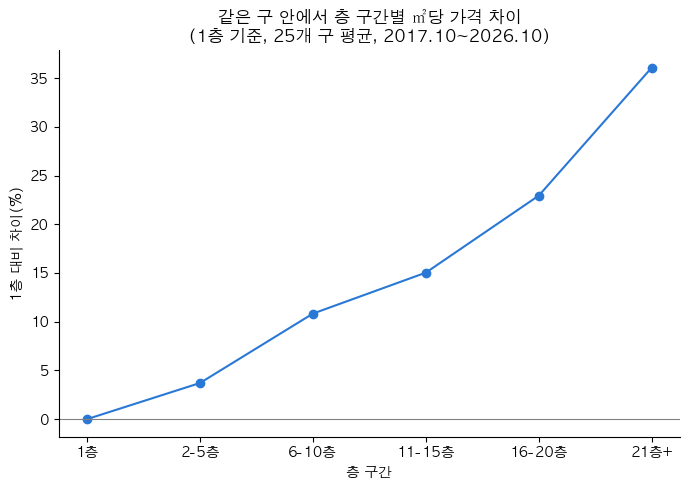

In [4]:
# 층을 6구간으로 나누고, 같은 구의 1층 대비 ㎡당 가격 차이(%)의 25개 구 평균을 그린다
# 1) 층 구간 나누기 (right=False: 2층이면 '2-5층'처럼 왼쪽 경계를 포함)
floor_bins = [1, 2, 6, 11, 16, 21, 100]
floor_labels = ['1층', '2-5층', '6-10층', '11-15층', '16-20층', '21층+']
df['층구간'] = pd.cut(df['층'], bins=floor_bins, labels=floor_labels, right=False)

# 2) 구(행) × 층구간(열) ㎡당 가격 중앙값 표 만들기
gu_floor = df.pivot_table(index='구', columns='층구간', values='㎡당가격(만원)', aggfunc='median', observed=True)

# 3) 같은 구의 1층 대비 차이(%) 구하기
gu_floor_diff = pd.DataFrame()
for col in floor_labels:
    gu_floor_diff[col] = (gu_floor[col] - gu_floor['1층']) / gu_floor['1층'] * 100

# 4) 25개 구의 평균 차이와 1층보다 비싼 구의 수 구하기
floor_mean = gu_floor_diff.mean()
floor_summary = pd.DataFrame({'평균_차이(%)': floor_mean,
                              '1층보다_비싼_구_수': (gu_floor_diff > 0).sum()})
print(floor_summary.round(1))

# 5) 점 + 선 그래프 그리기
plt.figure(figsize=(7, 5))
plt.plot(floor_labels, floor_mean, marker='o', color='#2a78d6', linewidth=1.5)
plt.axhline(0, color='gray', linewidth=0.8)  # 기준선(1층 = 0%)
plt.title('같은 구 안에서 층 구간별 ㎡당 가격 차이\n(1층 기준, 25개 구 평균, 2017.10~2026.10)')
plt.xlabel('층 구간')
plt.ylabel('1층 대비 차이(%)')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../outputs/02_구별_층구간별_제곱미터당가격.png', dpi=150)
plt.show()

## 5. 같은 구 안에서 연식 구간별 ㎡당 가격 비교

연식(계약 연도 − 건축년도)을 5개 구간으로 나누고, 3·4절과 같은 방법으로 **같은 구 안에서** 비교합니다.

| 구간 | 연식 | 거래 건수 |
| --- | --- | --- |
| 0-4년 | 4년 이하 (**기준**, 신축) | 약 4.2만 건 |
| 5-9년 | 5년 ~ 9년 | 약 5.7만 건 |
| 10-19년 | 10년 ~ 19년 | 약 15.7만 건 |
| 20-29년 | 20년 ~ 29년 | 약 16.7만 건 |
| 30년+ | 30년 이상 | 약 10.3만 건 |

계산 순서
1. 구마다 연식 구간별 ㎡당 가격 중앙값을 구합니다.
2. 같은 구의 **0-4년(신축)** 대비 몇 % 차이인지 계산합니다.
3. 25개 구의 차이를 평균 내어 점과 선으로 그립니다.

- 같은 연식 구간이라도 단지마다 위치·규모가 달라서, 연식 구간 사이의 차이에는 연식 자체뿐 아니라 **단지 특성의 차이**도 섞여 있을 수 있습니다.
- 도봉구(0-4년 363건, 5-9년 320건)와 종로구(30년+ 404건)는 거래가 적은 구간이 있어 해당 칸의 값은 흔들릴 수 있습니다.

        평균_차이(%)  신축보다_비싼_구_수
0-4년         0.0            0
5-9년       -10.3            5
10-19년     -30.7            1
20-29년     -23.3            3
30년+       -19.1            3


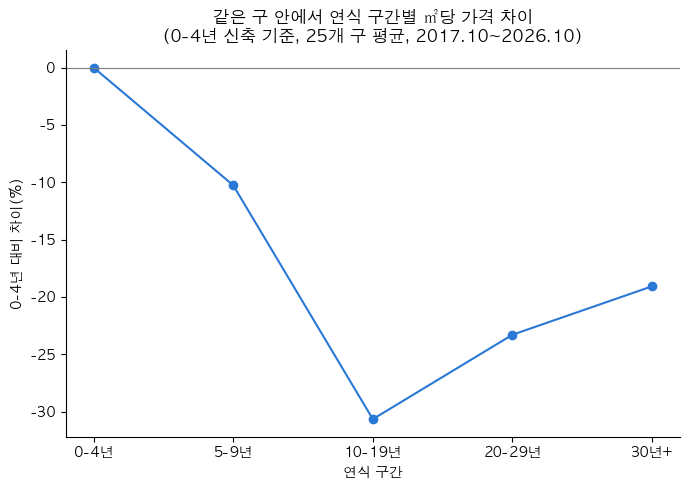

In [5]:
# 연식을 5구간으로 나누고, 같은 구의 신축(0-4년) 대비 ㎡당 가격 차이(%)의 25개 구 평균을 그린다
# 1) 연식 구간 나누기 (right=False: 5년이면 '5-9년'처럼 왼쪽 경계를 포함)
age_bins = [0, 5, 10, 20, 30, 100]
age_labels = ['0-4년', '5-9년', '10-19년', '20-29년', '30년+']
df['연식구간'] = pd.cut(df['연식'], bins=age_bins, labels=age_labels, right=False)

# 2) 구(행) × 연식구간(열) ㎡당 가격 중앙값 표 만들기
gu_age = df.pivot_table(index='구', columns='연식구간', values='㎡당가격(만원)', aggfunc='median', observed=True)

# 3) 같은 구의 0-4년(신축) 대비 차이(%) 구하기
gu_age_diff = pd.DataFrame()
for col in age_labels:
    gu_age_diff[col] = (gu_age[col] - gu_age['0-4년']) / gu_age['0-4년'] * 100

# 4) 25개 구의 평균 차이와 신축보다 비싼 구의 수 구하기
age_mean = gu_age_diff.mean()
age_summary = pd.DataFrame({'평균_차이(%)': age_mean,
                            '신축보다_비싼_구_수': (gu_age_diff > 0).sum()})
print(age_summary.round(1))

# 5) 점 + 선 그래프 그리기
plt.figure(figsize=(7, 5))
plt.plot(age_labels, age_mean, marker='o', color='#2a78d6', linewidth=1.5)
plt.axhline(0, color='gray', linewidth=0.8)  # 기준선(0-4년 = 0%)
plt.title('같은 구 안에서 연식 구간별 ㎡당 가격 차이\n(0-4년 신축 기준, 25개 구 평균, 2017.10~2026.10)')
plt.xlabel('연식 구간')
plt.ylabel('0-4년 대비 차이(%)')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../outputs/02_구별_연식구간별_제곱미터당가격.png', dpi=150)
plt.show()

## 6. 결론

**연구 질문 2: 아파트의 면적, 연식, 층과 가격은 어떤 관계가 있을까?**

서울 전체를 한꺼번에 비교하면 지역(구) 차이가 섞여 들어갑니다. 그래서 **같은 구 안에서** 구간별 ㎡당 가격을 비교했습니다.

- **면적:** 넓을수록 거래금액은 높습니다(상관계수 0.54). 그런데 ㎡당 가격으로 보면 40~60㎡ 구간이 가장 높습니다(60~85㎡보다 +16%). 85㎡ 이상부터는 넓을수록 ㎡당 가격이 낮아집니다(135㎡ 이상 -19%).
- **층:** 높을수록 ㎡당 가격이 높습니다. 1층과 비교하면 6-10층 +11%, 16-20층 +23%, 21층 이상 +36%입니다. 11층 이상은 25개 구 모두에서 1층보다 비쌌습니다.
- **연식:** 신축(0-4년)이 가장 비싸고, 10-19년이 가장 쌉니다(-31%). 20년이 넘으면 다시 높아집니다(30년 이상 -19%). 이렇게 내려갔다 올라가는 U자 모양이라, 직선 관계만 재는 상관계수는 거의 0(-0.02)으로 나왔습니다.

**주의할 점**
- 이 결과는 특성과 가격이 **함께 나타나는 관계**입니다. 그 특성이 가격을 올리거나 내린 원인이라고 단정할 수는 없습니다.
- 고층 거래는 높은 건물이 있는 단지에서만 나옵니다. 그래서 층과 연식의 차이에는 단지 특성(위치, 규모 등)이 섞여 있을 수 있습니다.
- 20년 이상에서 ㎡당 가격이 다시 높아지는 이유(재건축 기대, 입지 등)는 이 분석으로는 확인할 수 없습니다.